# Multi-wavelength photonic-lantern propagation

Propagates a batch of DM-aberrated input fields through the 19-port lantern
at every wavelength of a native grid (one characterized `ChainPropagator`
per wavelength, built and released one at a time by
`multi_wvl.MultiWavelengthPropagationPipeline`), giving each output fiber's
spectrum for each field. The spectra are then dispersed onto a simulated
spectrograph detector and extracted back (`spectral` package).

The aberration here is a ramp of DM mode 0 (a petal piston) from -5 to
+5 um. Each wavelength needs its own lantern characterization: minutes per
wavelength the first time, cached under `./data/` afterwards. The
propagation results are cached too (`RESULTS_FILE`), so later runs of this
notebook only redo the plots unless `RERUN = True`.

In [1]:
import os
os.environ["CBEAM_BACKEND"] = "numpy"

import numpy as np
import matplotlib.pyplot as plt

import batch_pipeline as bp
import multi_wvl as mw
from multi_wavelength_vis import (
    plot_spectra_grid, plot_fiber_spectra, plot_wavelength_fiber_heatmap,
    plot_ramp_response, plot_total_throughput_vs_amplitude,
    plot_per_fiber_throughput_vs_amplitude, plot_detector_stage_for_field,
)

WL_MIN_NM, WL_MAX_NM = 700.0, 900.0
WVL_SAMPLES    = 41                    # native wavelengths (5 nm steps)
PISTON_SAMPLES = 81                    # steps of the mode-0 ramp
PISTON_MAX_NM  = 5000.0                # ramp spans -PISTON_MAX_NM .. +PISTON_MAX_NM

RESULTS_FILE = f"data/mw_results_{WVL_SAMPLES}.npz"
RERUN = False                          # True: propagate again even if RESULTS_FILE exists

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


## Optional: mode bookkeeping across the band

Which modes are degenerate (and must be tracked as groups) and which one is
not guided changes with wavelength. `diagnose_mode_bookkeeping` infers it
from two FEM solves at the lantern ends, without characterizing anything;
`MultiWavelengthPropagationPipeline(..., auto_mode_bookkeeping=True)` does
the same for every wavelength it has to characterize from scratch. The scan
costs two FEM solves per wavelength, so it is off by default.

In [2]:
RUN_BOOKKEEPING_SCAN = False

base_params = bp.get_simulation_parameters(nrings=3)
native_wl_nm = np.linspace(WL_MIN_NM, WL_MAX_NM, WVL_SAMPLES)

if RUN_BOOKKEEPING_SCAN:
    lantern = mw.build_lantern_geometry(base_params)   # shared geometry, built once
    bookkeeping = {}
    for wl in native_wl_nm:
        print(f"\n### {wl:.0f} nm")
        front, back, skipped = mw.diagnose_mode_bookkeeping(base_params, wl, PL_N=lantern)
        bookkeeping[wl] = (front, back, skipped)
    ref = bookkeeping.get(800.0)
    print("\nwavelengths whose structure differs from 800 nm:",
          [f"{wl:.0f}" for wl, b in bookkeeping.items() if ref is not None and b != ref])

## Propagate the ramp at every native wavelength

`get_power_spectra` returns, for every wavelength, field and output fiber,
the fraction of the incident power that reaches that fiber (the input
coupling efficiency is folded in, so the spectra are comparable across
wavelengths and fields).

In [3]:
coeff_matrix, labels = bp.create_ramp_aberration_configs(
    [0], PISTON_SAMPLES, -PISTON_MAX_NM, PISTON_MAX_NM)
amplitudes = coeff_matrix[:, 0]

if os.path.exists(RESULTS_FILE) and not RERUN:
    data = np.load(RESULTS_FILE)
    power_spectra, wl_out = data["power_spectra"], data["wavelengths"]
    print(f"loaded {RESULTS_FILE}")
else:
    ifunc = bp.load_ifunc(base_params["ifunc_file"])   # through specula if installed
    bp.center_ifunc_mask(ifunc)
    mwp = mw.MultiWavelengthPropagationPipeline(
        base_params=base_params,
        ifunc=ifunc,
        native_wavelengths_nm=native_wl_nm,
        auto_mode_bookkeeping=True,       # only used for wavelengths not cached yet
        verbose=False,
    )
    power_spectra, wl_out = mwp.get_power_spectra(coeff_matrix, prop_chunk_size=32)
    np.savez(RESULTS_FILE, power_spectra=power_spectra, wavelengths=wl_out,
             coeff_matrix=coeff_matrix, labels=labels)
    print(f"saved {RESULTS_FILE}")

print(f"power_spectra: {power_spectra.shape} (wavelengths, fields, fibers)")

2026-10-15 18:43:31,018 [INFO]: [specula]: Cupy import successfull. Installed version is: 14.1.1


2026-10-15 18:43:31,019 [INFO]: [specula]: Default device is CPU


[Interpolation Setup]
  Padded grid size: 1600
  Grid parity: even
  Center offset: 800.0
  Pixel scale: 0.4841188524590164 μm/pixel
  Mesh X range: [-27.000, 27.000] μm
  Mesh Y range: [-26.852, 26.852] μm
  Valid interpolation points: 12495 / 12495
  Generating modal coefficients for 81 fields (chunk_size=64, device=CPU) ...


    field-gen chunk 0–63 done.


    field-gen chunk 64–80 done.


  Field generation complete.
  Propagating 81 fields (chunk_size=32) ...


... (321 outputs left out)

    propagation chunk 32–63 done.


    propagation chunk 64–80 done.


  (us_batch not returned for multi-chunk runs to save memory)
  Batch propagation complete.


saved data/mw_results_41.npz
power_spectra: (41, 81, 19) (wavelengths, fields, fibers)


## Output spectra

For the unaberrated field (the middle of the ramp), then along the ramp.

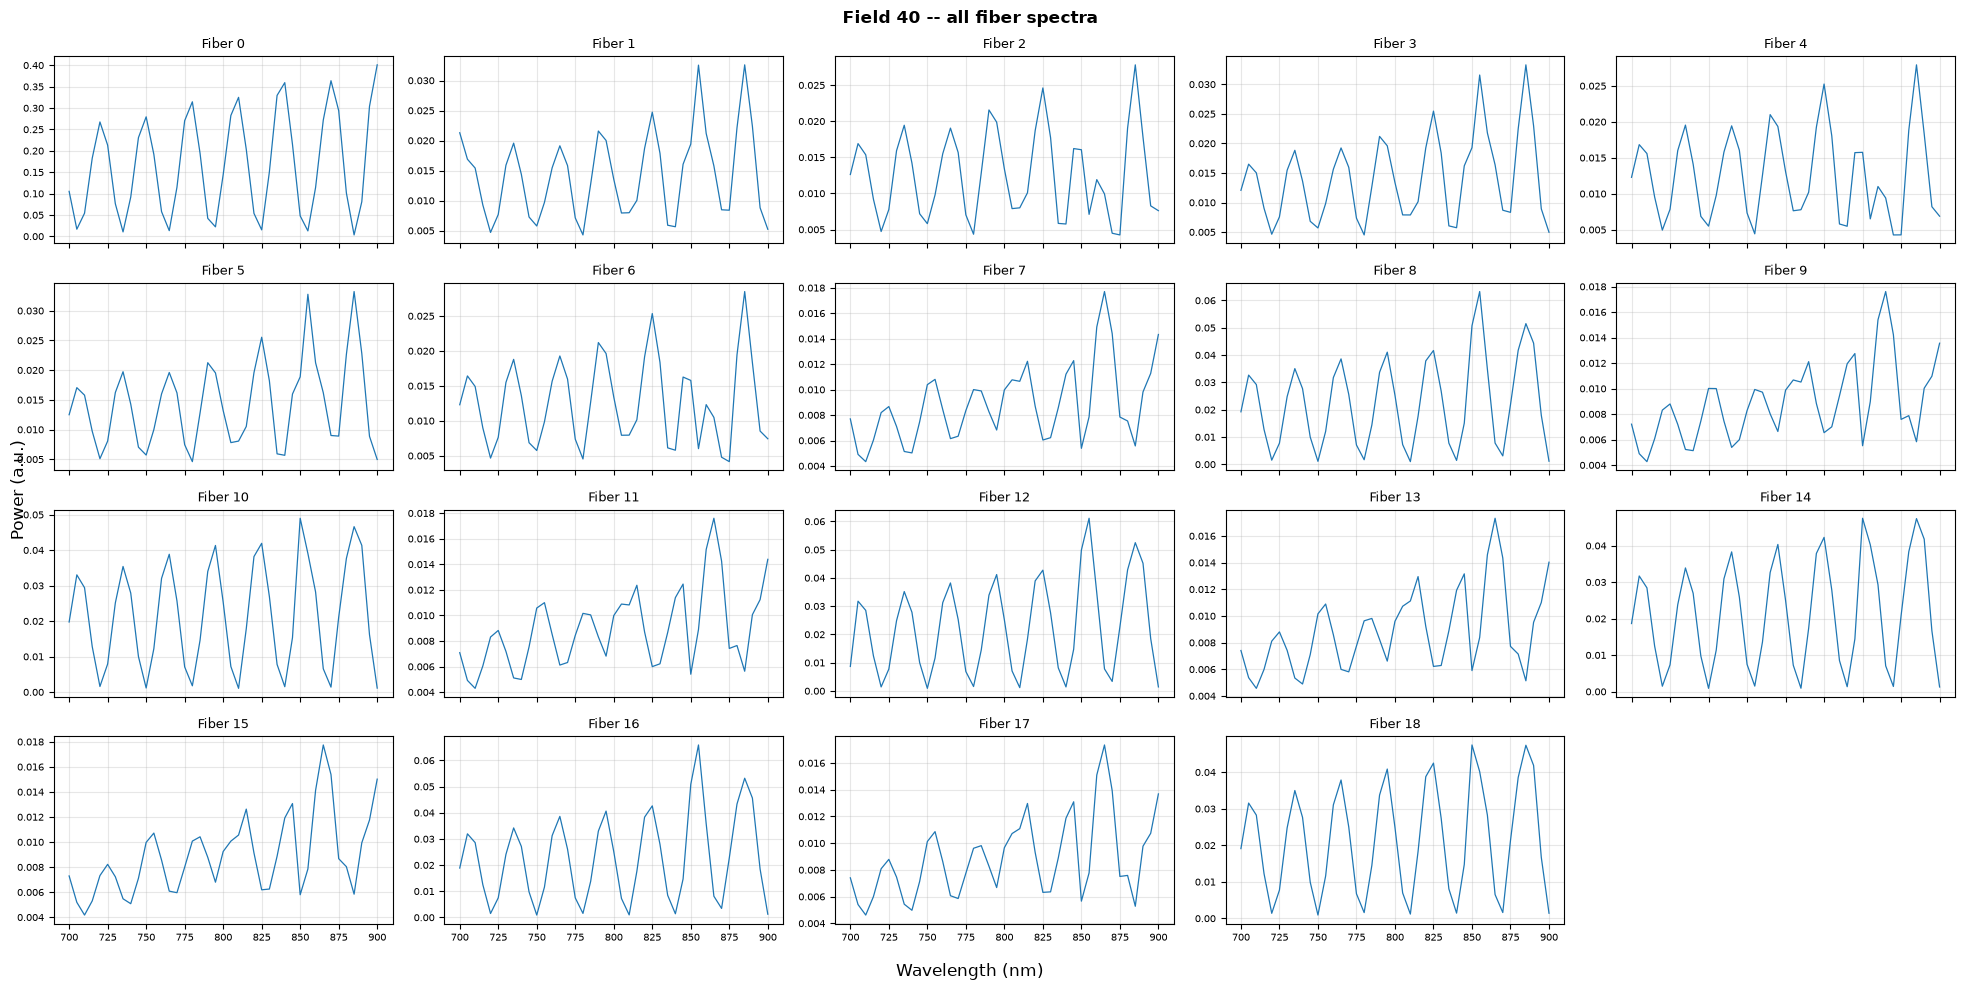

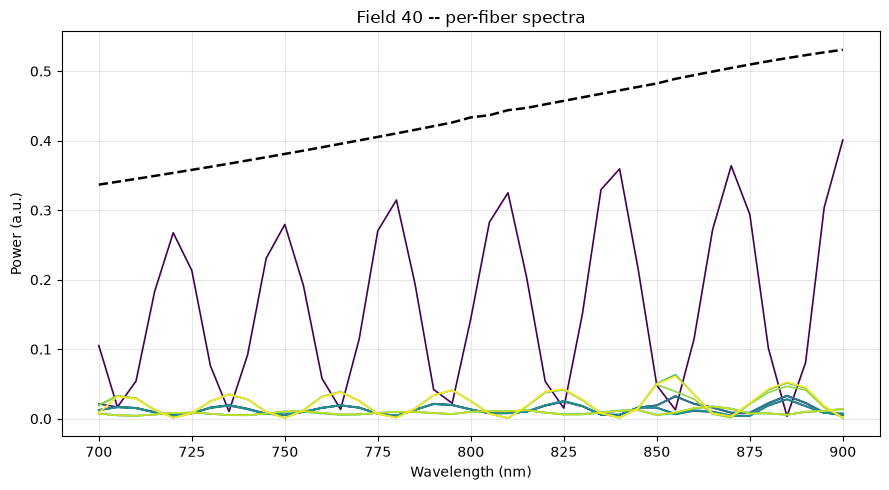

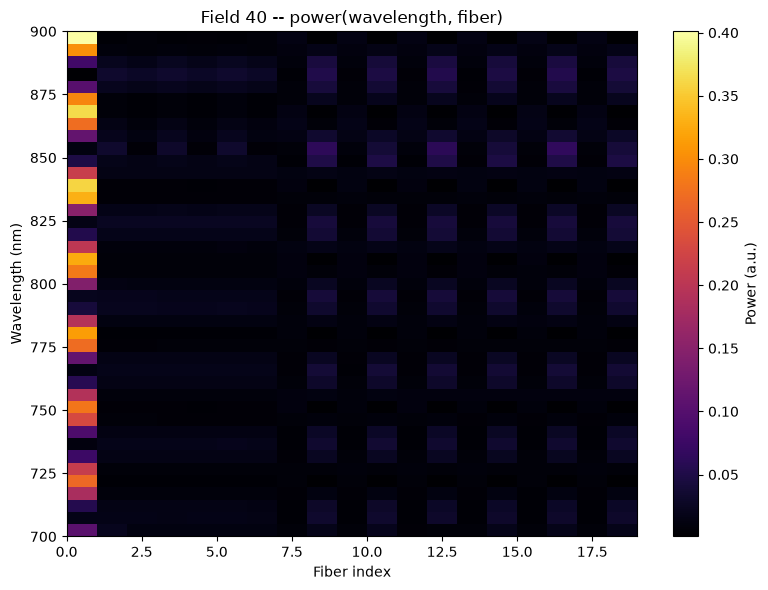

<Axes: title={'center': 'Field 40 -- power(wavelength, fiber)'}, xlabel='Fiber index', ylabel='Wavelength (nm)'>

In [4]:
field_idx = PISTON_SAMPLES // 2          # zero piston

plot_spectra_grid(power_spectra, wl_out, field_idx=field_idx)
plot_fiber_spectra(power_spectra, wl_out, field_idx=field_idx,
                   fiber_indices=list(range(13)), plot_sum=True)
plot_wavelength_fiber_heatmap(power_spectra, wl_out, field_idx=field_idx)

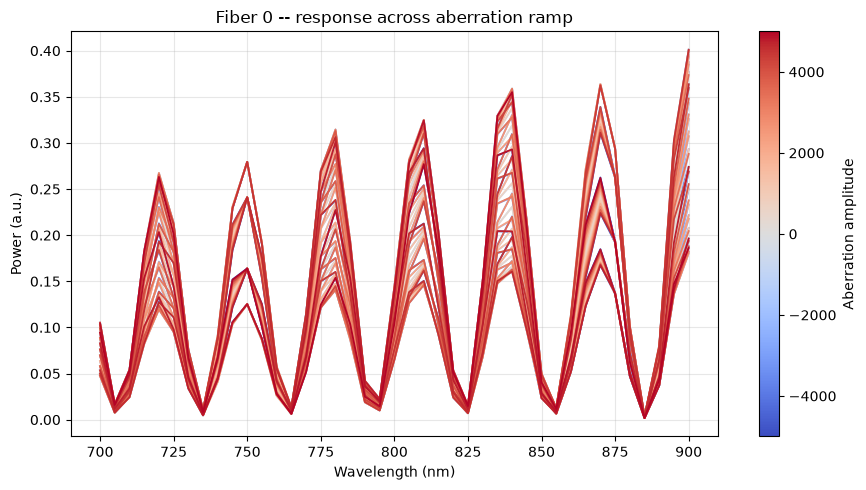

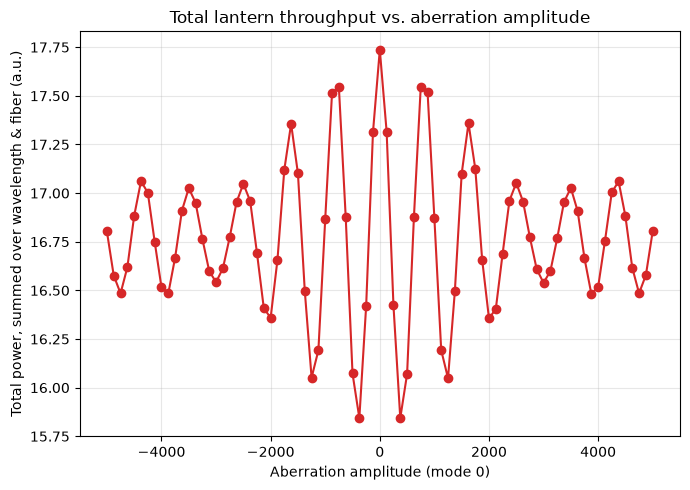

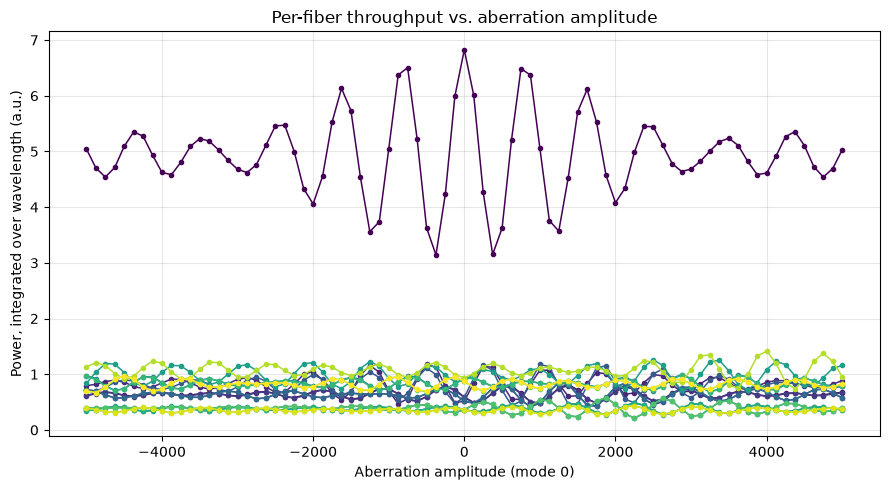

In [5]:
plot_ramp_response(power_spectra, wl_out, amplitudes, fiber_idx=0, labels=labels)
plot_total_throughput_vs_amplitude(power_spectra, amplitudes, labels=labels, mode_label="mode 0")
plot_per_fiber_throughput_vs_amplitude(power_spectra, amplitudes, mode_label="mode 0")

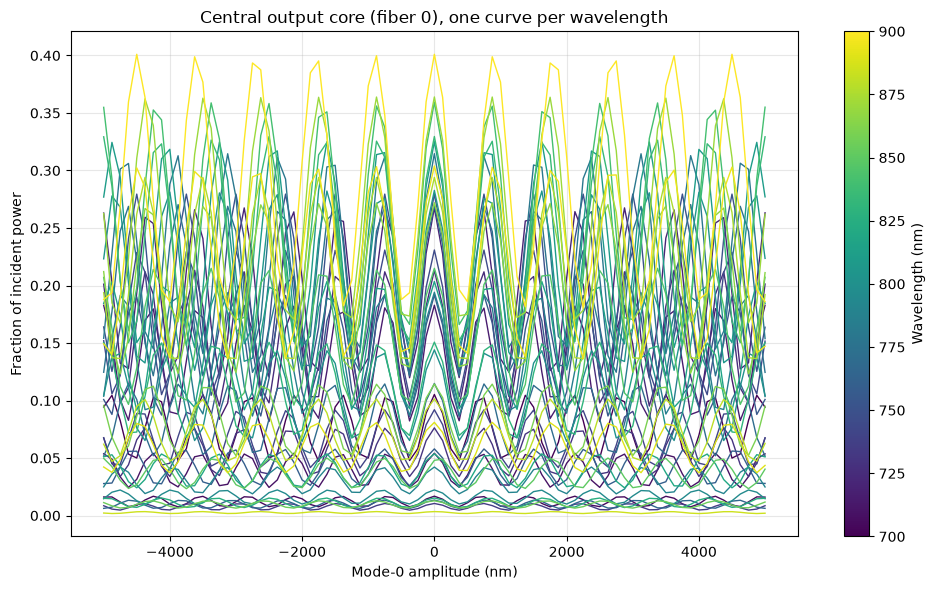

In [6]:
# Central output core: one curve per wavelength along the ramp
central_core = 0
fig, ax = plt.subplots(figsize=(10, 6))
norm = plt.Normalize(wl_out.min(), wl_out.max())
for w, wl in enumerate(wl_out):
    ax.plot(amplitudes, power_spectra[w, :, central_core],
            color=plt.cm.viridis(norm(wl)), lw=1.0)
ax.set_xlabel("Mode-0 amplitude (nm)")
ax.set_ylabel("Fraction of incident power")
ax.set_title(f"Central output core (fiber {central_core}), one curve per wavelength")
ax.grid(True, alpha=0.3)
fig.colorbar(plt.cm.ScalarMappable(cmap="viridis", norm=norm), ax=ax, label="Wavelength (nm)")
plt.tight_layout()
plt.show()

## Input coupling across the band

Summed over the fibers, the unaberrated field's spectrum is the fraction of
the incident power that couples into the lantern's tracked modes (propagation
is lossless apart from the one untracked mode), so it shows how the coupling changes with wavelength as
the PSF scales with lambda relative to the fixed input face.

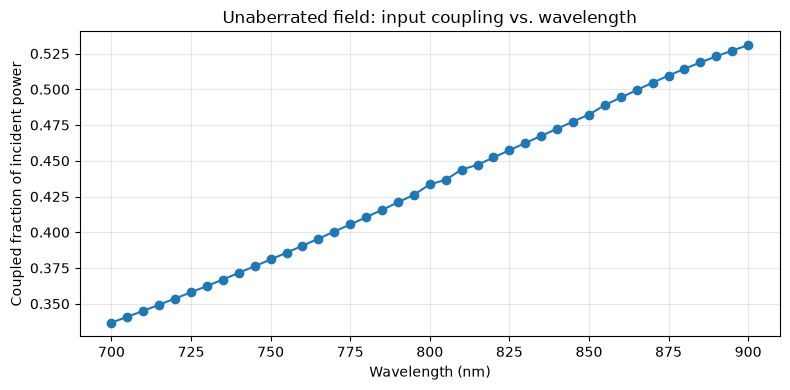

    700 nm    33.7%
    725 nm    35.8%
    750 nm    38.1%
    775 nm    40.5%
    800 nm    43.3%
    825 nm    45.7%
    850 nm    48.2%
    875 nm    51.0%
    900 nm    53.1%


In [7]:
coupled = power_spectra[:, field_idx, :].sum(axis=1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(wl_out, coupled, "o-")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Coupled fraction of incident power")
ax.set_title("Unaberrated field: input coupling vs. wavelength")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
for wl, c in list(zip(wl_out, coupled))[::5]:
    print(f"  {wl:5.0f} nm   {c:6.1%}")

## Spectrograph detector stage

The unaberrated field's spectra, scaled to `photons_per_nm` photons entering
the lantern per nm of bandwidth, dispersed onto the simulated detector
(with noise) and extracted back with optimal extraction.

SpectralImageSimulator initialized:
  Wavelength range: 700.0-900.0 nm
  Spectral bins: 41
  Dispersion: 3.333 pix/nm
  Detector: 2048 x 512 pixels


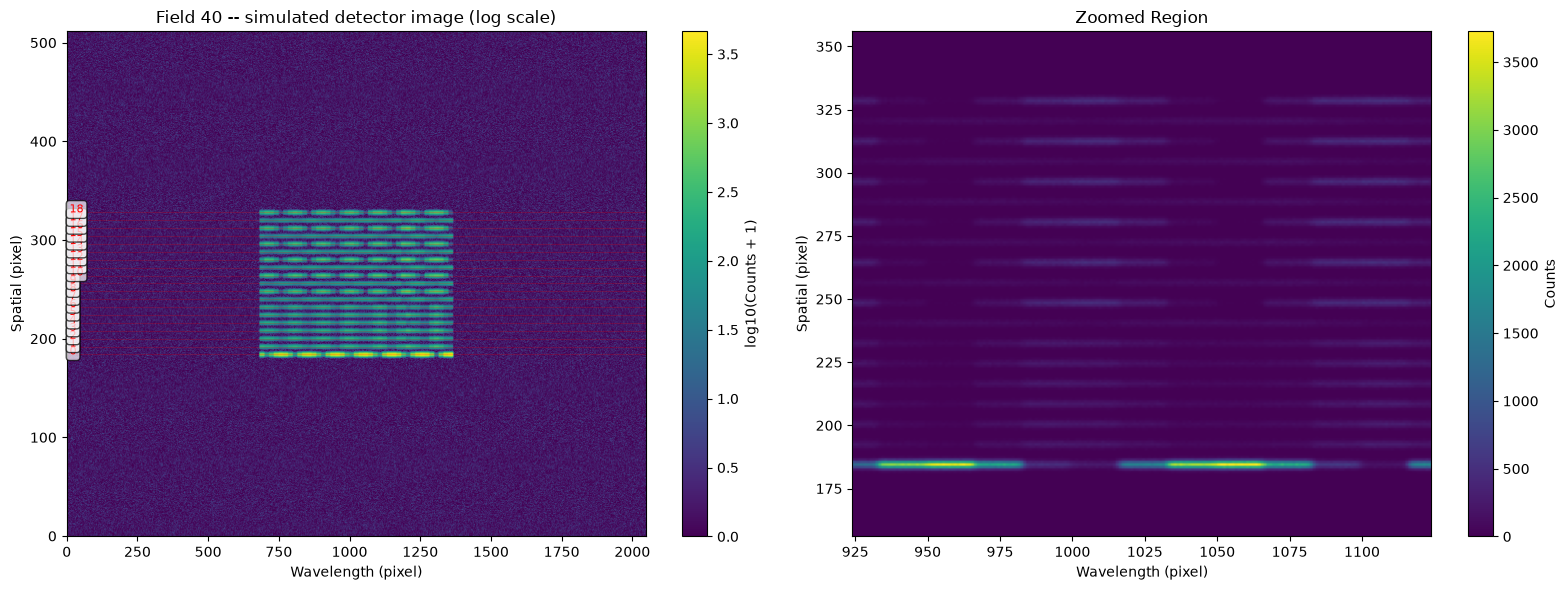

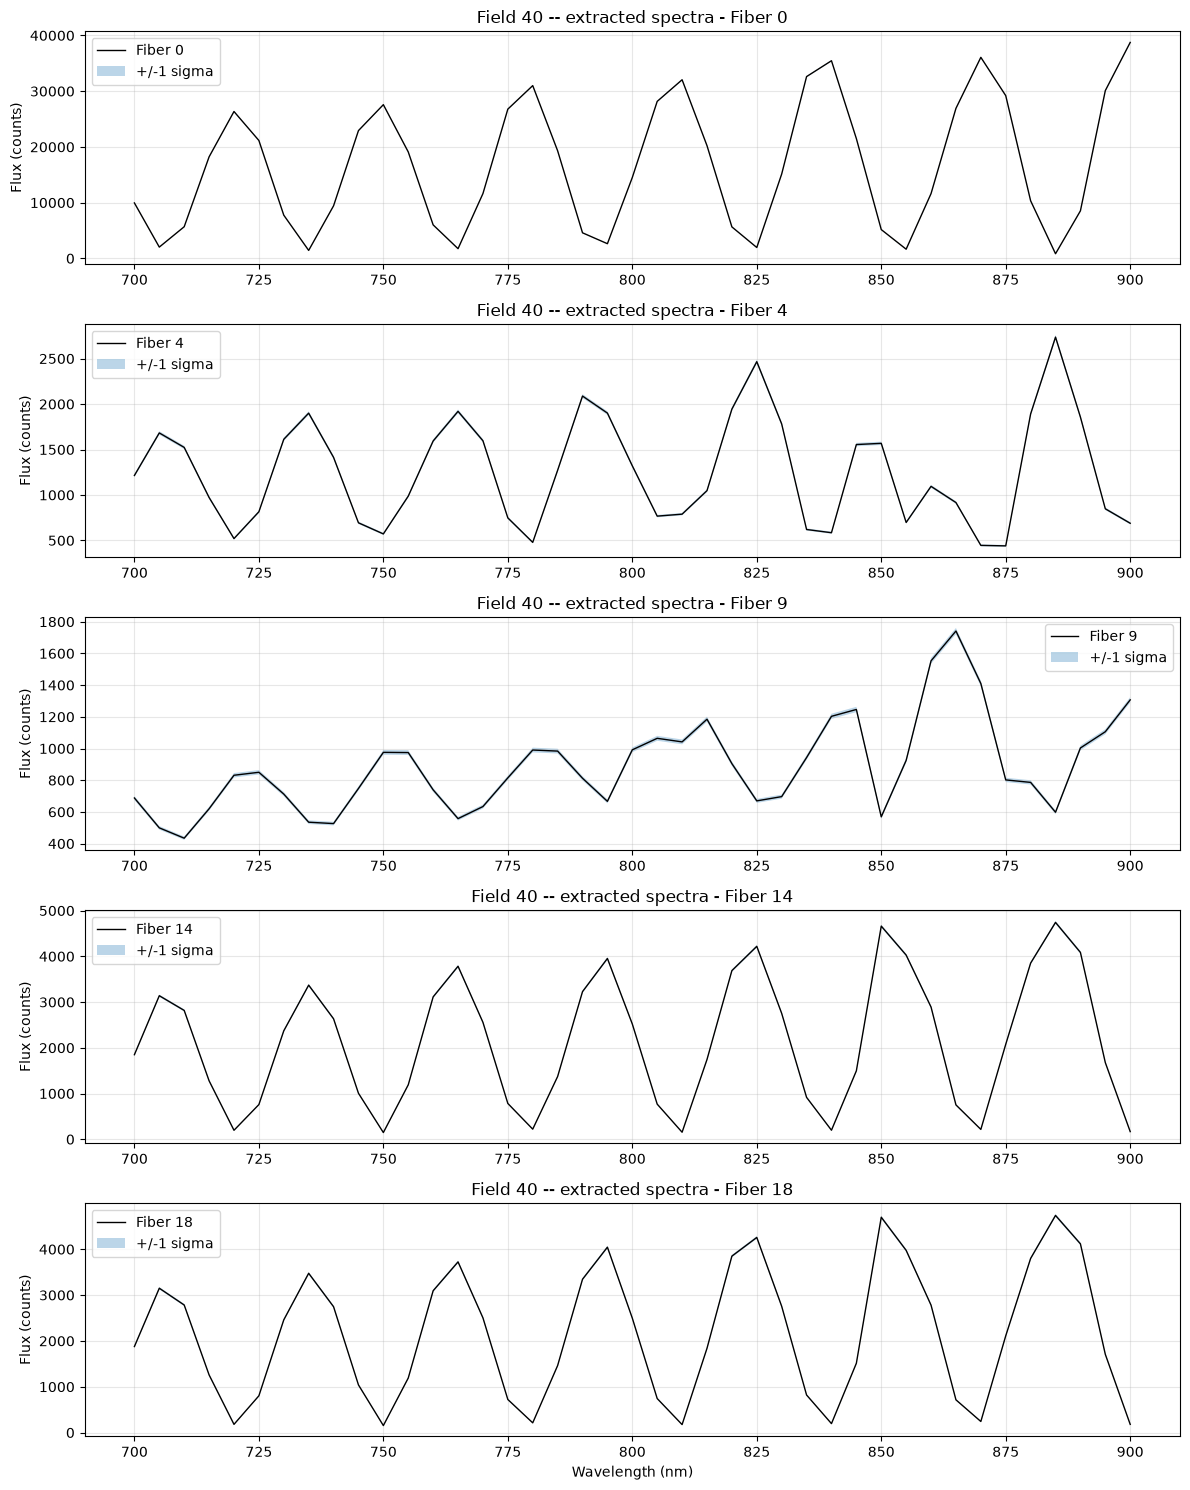

In [8]:
image, extracted, variance = plot_detector_stage_for_field(
    power_spectra, wl_out, field_idx=field_idx, photons_per_nm=1e5)